In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

%matplotlib inline

In [3]:
grades = pd.read_csv('grades.csv')

grades

,Name,StudyHours,Grade
0,Dan,10.00,50.0
1,Joann,11.50,50.0
2,Pedro,9.00,47.0
3,Rosie,16.00,97.0
4,Ethan,9.25,49.0
5,Vicky,1.00,3.0
6,Frederic,11.50,53.0
7,Jimmie,9.00,42.0
8,Rhonda,8.50,26.0
9,Giovanni,14.50,74.0


In [4]:
grades.info()

print("\n" + "="*50 + "\n")

grades.head()

print("\n" + "="*50 + "\n")

grades.tail()

<class 'pandas.DataFrame'>
RangeIndex: 24 entries, 0 to 23
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Name        24 non-null     str    
 1   StudyHours  23 non-null     float64
 2   Grade       22 non-null     float64
dtypes: float64(2), str(1)
memory usage: 838.0 bytes






,Name,StudyHours,Grade
19,Skye,12.0,52.0
20,Daniel,12.5,63.0
21,Aisha,12.0,64.0
22,Bill,8.0,NaN
23,Ted,NaN,NaN


In [5]:
grades.describe()

print("\n" + "="*50 + "\n")

grades.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
StudyHours,23.0,10.413043,3.447338,1.0,8.75,10.0,12.25,16.0
Grade,22.0,49.181818,21.737912,3.0,36.25,49.5,62.75,97.0


Pass/Fail Count:
passed
0    13
1    11
Name: count, dtype: int64


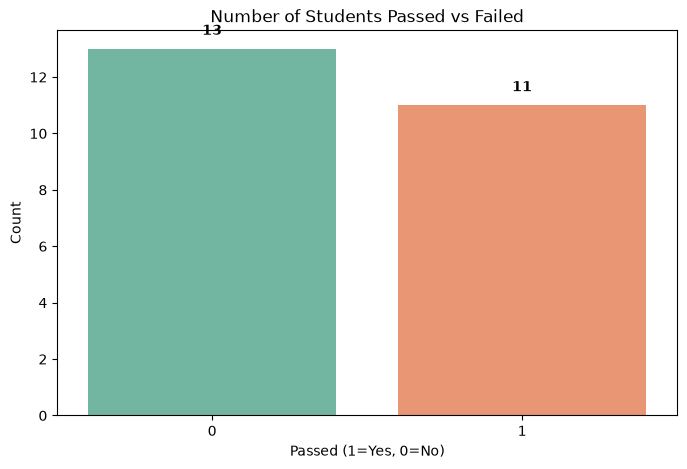

In [7]:
grades['passed'] = grades['Grade'].apply(lambda x: 1 if x >= 50 else 0)

print("Pass/Fail Count:")
print(grades['passed'].value_counts())

plt.figure(figsize=(8, 5))
sns.countplot(data=grades, x='passed', hue='passed', palette='Set2', legend=False)
plt.title('Number of Students Passed vs Failed')
plt.xlabel('Passed (1=Yes, 0=No)')
plt.ylabel('Count')

for i, v in enumerate(grades['passed'].value_counts().sort_index()):
    plt.text(i, v + 0.5, str(v), ha='center', fontweight='bold')

plt.show()

In [8]:
def category_hours(hours):
    if pd.isna(hours):
        return 'Unknown'
    elif hours < 10:
        return 'Low (<10)'
    elif hours < 13:
        return 'Medium (10-13)'
    else:
        return 'High (>13)'

grades['hour_category'] = grades['StudyHours'].apply(category_hours)

print("Study Hours Categories:")
print(grades['hour_category'].value_counts())

Study Hours Categories:
hour_category
Low (<10)         11
Medium (10-13)     7
High (>13)         5
Unknown            1
Name: count, dtype: int64


In [9]:
less_than_10 = grades[grades['StudyHours'] < 10]

print(f"Students who studied less than 10 hours: {len(less_than_10)}")
print("\nFirst 5 students:")
less_than_10.head()

Students who studied less than 10 hours: 11

First 5 students:


,Name,StudyHours,Grade,passed,hour_category
2,Pedro,9.00,47.0,0,Low (<10)
4,Ethan,9.25,49.0,0,Low (<10)
5,Vicky,1.00,3.0,0,Low (<10)
7,Jimmie,9.00,42.0,0,Low (<10)
8,Rhonda,8.50,26.0,0,Low (<10)


In [10]:
less_than_10 = grades[grades['StudyHours'] < 10]

print(f"Students who studied less than 10 hours: {len(less_than_10)}")
print("\nFirst 5 students:")
less_than_10.head()

Students who studied less than 10 hours: 11

First 5 students:


,Name,StudyHours,Grade,passed,hour_category
2,Pedro,9.00,47.0,0,Low (<10)
4,Ethan,9.25,49.0,0,Low (<10)
5,Vicky,1.00,3.0,0,Low (<10)
7,Jimmie,9.00,42.0,0,Low (<10)
8,Rhonda,8.50,26.0,0,Low (<10)


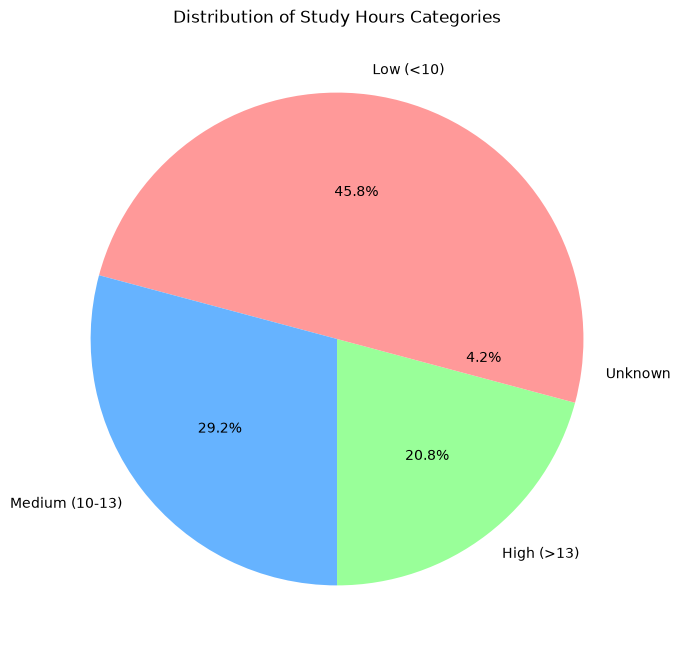

In [11]:
plt.figure(figsize=(8, 8))
grades['hour_category'].value_counts().plot(kind='pie', autopct='%1.1f%%', 
                                            colors=['#ff9999','#66b3ff','#99ff99'])
plt.title('Distribution of Study Hours Categories')
plt.ylabel('')  
plt.show()

Number of unique students: 24


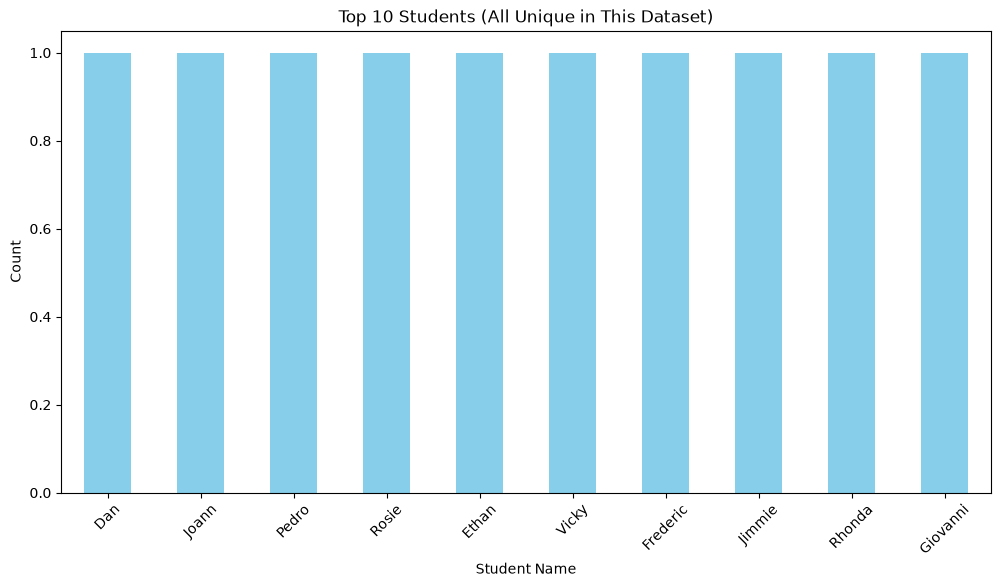

In [12]:
print(f"Number of unique students: {grades['Name'].nunique()}")

plt.figure(figsize=(12, 6))
grades['Name'].value_counts().head(10).plot(kind='bar', color='skyblue')
plt.title('Top 10 Students (All Unique in This Dataset)')
plt.xlabel('Student Name')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

Missing values per column:
Name             0
StudyHours       1
Grade            2
passed           0
hour_category    0
dtype: int64


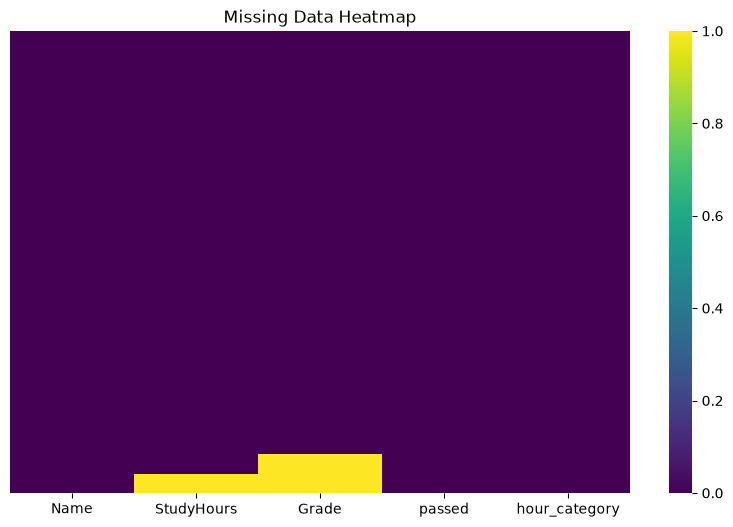

In [13]:
print("Missing values per column:")
print(grades.isnull().sum())

plt.figure(figsize=(10, 6))
sns.heatmap(grades.isnull(), yticklabels=False, cbar=True, cmap='viridis')
plt.title('Missing Data Heatmap')
plt.show()

In [14]:
grades['Grade'] = grades['Grade'].fillna(grades['Grade'].median())
grades['StudyHours'] = grades['StudyHours'].fillna(grades['StudyHours'].mean())

print("Missing values after filling:")
print(grades.isnull().sum())

Missing values after filling:
Name             0
StudyHours       0
Grade            0
passed           0
hour_category    0
dtype: int64


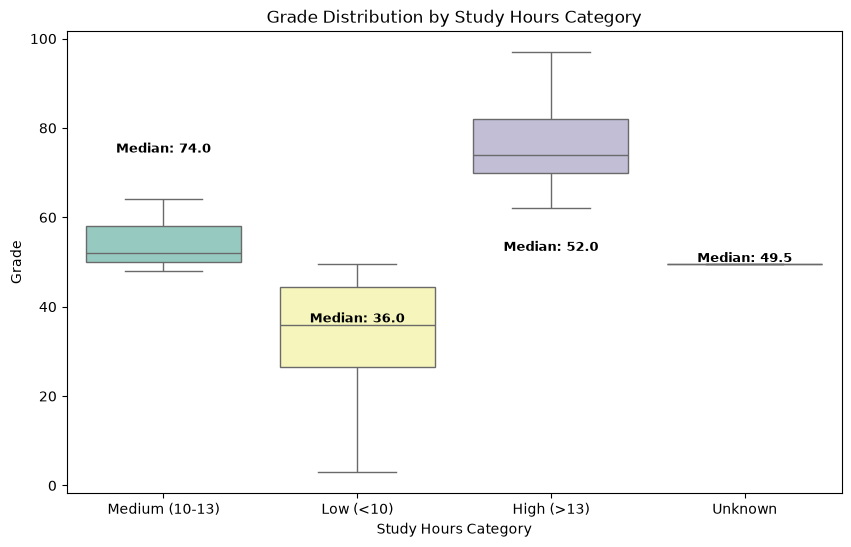

In [16]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=grades, x='hour_category', y='Grade', 
            hue='hour_category', palette='Set3', legend=False)
plt.title('Grade Distribution by Study Hours Category')
plt.xlabel('Study Hours Category')
plt.ylabel('Grade')

medians = grades.groupby('hour_category')['Grade'].median()
for i, (category, median) in enumerate(medians.items()):
    plt.text(i, median + 0.5, f'Median: {median}', ha='center', fontweight='bold', fontsize=9)

plt.show()

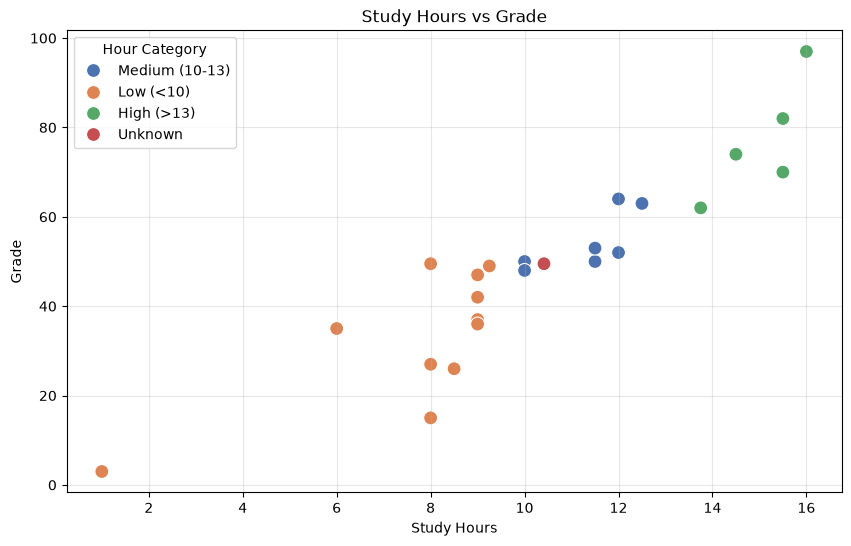

In [17]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=grades, x='StudyHours', y='Grade', 
                hue='hour_category', s=100, palette='deep')
plt.title('Study Hours vs Grade')
plt.xlabel('Study Hours')
plt.ylabel('Grade')
plt.grid(True, alpha=0.3)
plt.legend(title='Hour Category')
plt.show()

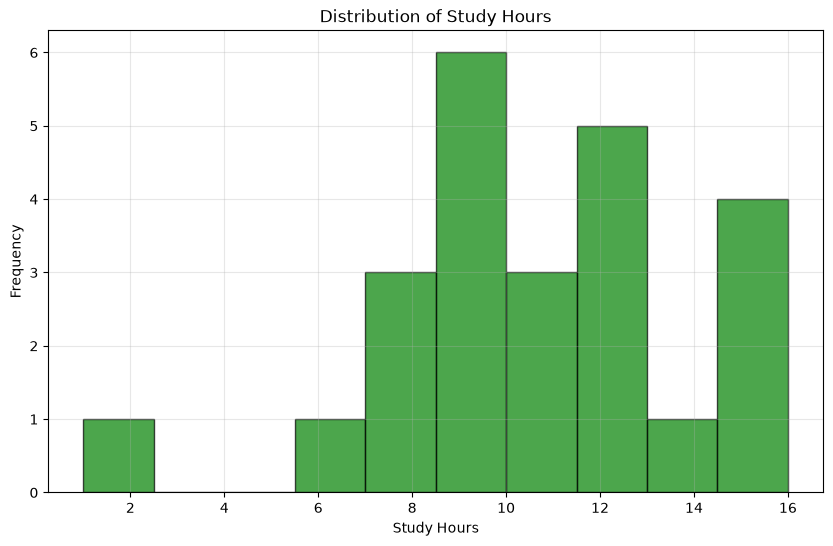

In [18]:
plt.figure(figsize=(10, 6))
grades['StudyHours'].plot(kind='hist', bins=10, color='green', alpha=0.7, 
                          edgecolor='black')
plt.title('Distribution of Study Hours')
plt.xlabel('Study Hours')
plt.ylabel('Frequency')
plt.grid(True, alpha=0.3)
plt.show()

Correlation Matrix:
            StudyHours     Grade
StudyHours    1.000000  0.914106
Grade         0.914106  1.000000

Correlation with Grade:
StudyHours    0.914106
Grade         1.000000
Name: Grade, dtype: float64


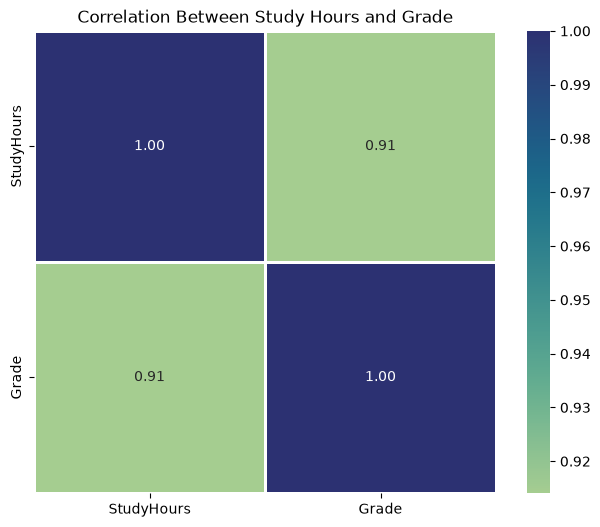

In [19]:
correlation = grades[['StudyHours', 'Grade']].corr()
print("Correlation Matrix:")
print(correlation)

print("\nCorrelation with Grade:")
print(correlation['Grade'])

plt.figure(figsize=(8, 6))
sns.heatmap(correlation, annot=True, cmap='crest', 
            fmt='.2f', square=True, linewidths=2)
plt.title('Correlation Between Study Hours and Grade')
plt.show()

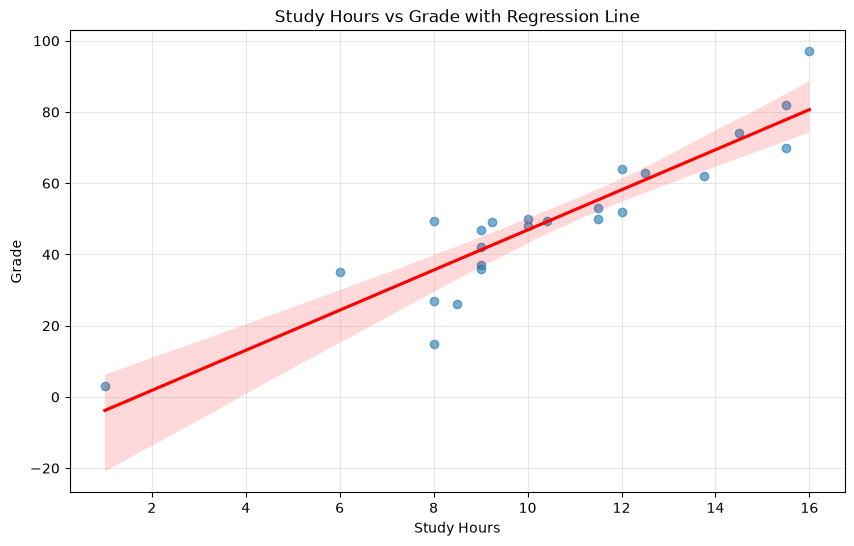

In [20]:
plt.figure(figsize=(10, 6))
sns.regplot(data=grades, x='StudyHours', y='Grade', 
            scatter_kws={'alpha':0.6}, line_kws={'color':'red'})
plt.title('Study Hours vs Grade with Regression Line')
plt.xlabel('Study Hours')
plt.ylabel('Grade')
plt.grid(True, alpha=0.3)
plt.show()

In [21]:
summary = grades.groupby('hour_category')['Grade'].agg(['mean', 'median', 'count'])
print("Grade Statistics by Study Hours Category:")
print(summary)

Grade Statistics by Study Hours Category:
                     mean  median  count
hour_category                           
High (>13)      77.000000    74.0      5
Low (<10)       33.318182    36.0     11
Medium (10-13)  54.285714    52.0      7
Unknown         49.500000    49.5      1
